# 05 – Spread model

Can the shape of the range curve be explained by a few centres, each spreading at the same constant speed?

## Idea

Skellam (1951): a population that grows and disperses at random spreads from its starting point as a circle whose radius grows at a constant speed *c* (for large t, *c* = 2√(rD)). One centre gives a straight line for √(area) against year. Several centres that start at different times make the total √(area) bend upward while new centres appear, even though no centre spreads faster.

So the acceleration after 2010 (`04_effort-correction`: 1.7 → 4 km/yr) has two possible explanations:

1. **Faster spread:** the parakeets really spread faster after 2010.
2. **New centres:** the speed stayed the same, but populations in other cities started spreading too.

## Model

- **Centres:** London, Birmingham, Manchester, Glasgow, Cardiff: the largest cities, where escaped or released pet birds are most likely, and the centres visible in `hectads_by_year.mp4`.
- **Spread:** from its start year, each centre occupies a circle with radius *c* × (years since start), plus the 10 km square it lies in. A 10 km square counts as occupied when its centre lies in a circle. Overlapping circles count once; only Great Britain land squares count (the same 2,843 squares as in `04`).
- **Parameters:** one speed *c* for all centres, and one start year per centre.

Population size is not modelled: the data are presence per square, not bird counts.

## Fit

- **Data:** the effort-corrected range (`range_index.csv`), 1970–2025, atlas start years left out, as in `04`. Least squares on √(area); RMSE in km of √(area).
- **Start-year bounds:** from 5 years before the first parakeet record within 25 km of the city (birds may have been there a little before they were first recorded) to 2025.
- **Search:** start years are whole years. London alone (2 parameters) is searched exhaustively. Five centres (6 parameters) use coordinate descent: each start year in turn is set to its best value with the others fixed, then the speed, until nothing improves; repeated from 40 random starting points, keeping the best.
- **Two models:** London only, and five centres.

## Caveats

- **Observer effect:** cities have more birdwatchers and more escaped cage birds. New "centres" may partly be where people look. The effort correction covers which squares were visited, not how intensively, so this is not corrected.
- Circles ignore the sea and habitat: a circle around Cardiff reaches across the Bristol Channel, and uplands count as much as suburbs.
- Free start years make the model flexible. The fit is to the total area only, which doesn't say which city added which squares, so the start years of the smaller centres are less certain than the speed (see "How well are the parameters determined?").

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sys.path.insert(0, "../src")  # shared helpers in src/
from grid import gb_land_hectads, load_countries
from pipeline import FIRST_YEAR

PRESENCE_PATH = Path("../data/processed/presence_10km.csv.gz")   # 04_effort-correction
RANGE_INDEX_PATH = Path("../data/processed/range_index.csv")     # 04_effort-correction
LAND_PATH = Path("../data/external/ne_10m_admin_0_countries.zip")
PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")

LAST_YEAR = 2025                         # 2026 is incomplete
FIT_START = 1970                         # as in 04
ATLAS_START_YEARS = [1968, 1981, 1988]   # left out of the fits, as in 04
PARAKEET_LABEL = "Ring-necked Parakeet"
BENCHMARKS = ["Wren", "Robin", "Blackbird", "Blue Tit"]

# City centres, British National Grid in km (easting, northing)
CENTRES = {
    "London": (530, 180),
    "Birmingham": (407, 287),
    "Manchester": (384, 398),
    "Glasgow": (259, 665),
    "Cardiff": (318, 176),
}

FIRST_RECORD_RADIUS = 25  # km around the city centre for its first record
START_MARGIN = 5          # start year may be up to this many years before the first record
SPEEDS = np.arange(0.2, 8.0, 0.02)  # km/yr, grid for the speed
N_RESTARTS = 40           # random starting points for the five-centre search
SEED = 1

# Colours, as in 03 and 04
OBSERVED = "#2a78d6"     # blue
LONDON_ONLY = "#eb6834"  # orange
FIVE_CENTRES = "#1baf7a" # green
TEXT, MUTED, GRID = "#333333", "#898781", "#e1e0d9"
LAND, LAND_EDGE = "#f0efec", "#898781"

## Data

- Parakeet and benchmark presence per 10 km square and year (`presence_10km.csv.gz`, Great Britain, 1963–2025).
- Effort-corrected range per year (`range_index.csv`): the curve the model is fitted to.
- Persistent squares (parakeets also the year before or after, as in `04`), for the map comparison.

In [2]:
presence = pd.read_csv(PRESENCE_PATH)
range_index = pd.read_csv(RANGE_INDEX_PATH, index_col="year")

# All 10 km land squares in Great Britain, with their centres in km
gb_squares = sorted(gb_land_hectads(load_countries(LAND_PATH)))
gb_index = pd.Index(gb_squares)
N_GB_SQUARES = len(gb_squares)
corner = np.array([s.split("_") for s in gb_squares], dtype=float)
square_centre = corner + 5  # square ID = south-west corner in km

years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
observed = range_index.loc[years, "sqrt_area_corrected"]
fit_mask = (years >= FIT_START) & ~np.isin(years, ATLAS_START_YEARS)

parakeet = presence[presence["species"] == PARAKEET_LABEL].copy()
parakeet[["e", "n"]] = parakeet["hectad"].str.split("_", expand=True).astype(int) + 5  # square centre, km
parakeet_sets = parakeet.groupby("year")["hectad"].agg(set)

# Persistent squares (as in 04): a parakeet square counts in year t only with parakeets in t-1 or t+1 too
persistent_sets = pd.Series({
    y: {sq for sq in parakeet_sets.get(y, set())
        if sq in parakeet_sets.get(y - 1, set()) or sq in parakeet_sets.get(y + 1, set())}
    for y in years
})
print(f"{N_GB_SQUARES:,} GB land squares; {fit_mask.sum()} years in the fit "
      f"({FIT_START}–{LAST_YEAR} without {ATLAS_START_YEARS})")

2,843 GB land squares; 54 years in the fit (1970–2025 without [1968, 1981, 1988])


## Start-year bounds

First parakeet record within 25 km of each city, and the earliest allowed start year (5 years before it).

In [3]:
def first_record(x, y, radius=FIRST_RECORD_RADIUS):
    near = np.hypot(parakeet["e"] - x, parakeet["n"] - y) <= radius
    return int(parakeet.loc[near, "year"].min())


bounds = pd.DataFrame({"first record": {name: first_record(*xy) for name, xy in CENTRES.items()}})
bounds["earliest start"] = bounds["first record"] - START_MARGIN
bounds["latest start"] = LAST_YEAR
bounds.rename_axis("centre")

,first record,earliest start,latest start
centre,,,
London,1968,1963,2025
Birmingham,1984,1979,2025
Manchester,1977,1972,2025
Glasgow,1988,1983,2025
Cardiff,1972,1967,2025


## Model and search

`occupancy(c, starts)` returns a years × squares table of occupied squares. The fit minimises the squared difference in √(area) over the fit years.

In [4]:
# Distance from every square centre to every city centre, and each city's own square
DIST = {name: np.hypot(square_centre[:, 0] - x, square_centre[:, 1] - y) for name, (x, y) in CENTRES.items()}
OWN = {name: (np.abs(square_centre[:, 0] - x) <= 5) & (np.abs(square_centre[:, 1] - y) <= 5)
       for name, (x, y) in CENTRES.items()}


def occupancy(c, starts):
    # Boolean array (years x squares): occupied with speed c (km/yr) and start years {centre: year}
    occupied = np.zeros((len(years), N_GB_SQUARES), dtype=bool)
    for name, t0 in starts.items():
        since = years - t0
        radius = np.where(since >= 0, c * since, -1.0)  # -1: not started yet
        occupied |= DIST[name][None, :] <= radius[:, None]
        occupied |= (since >= 0)[:, None] & OWN[name][None, :]
    return occupied


def model_sqrt_area(c, starts):
    return pd.Series(np.sqrt(occupancy(c, starts).sum(axis=1) * 100), index=years)


def sse(c, starts):
    return float(((model_sqrt_area(c, starts) - observed).to_numpy()[fit_mask] ** 2).sum())


def rmse_from_sse(value):
    return np.sqrt(value / fit_mask.sum())


def best_speed(starts):
    errors = [sse(c, starts) for c in SPEEDS]
    i = int(np.argmin(errors))
    return float(SPEEDS[i]), errors[i]


def coordinate_descent(starts, c=None):
    # Improve start years one at a time (and the speed, unless c is given) until nothing improves
    fixed_speed = c is not None
    if fixed_speed:
        error = sse(c, starts)
    else:
        c, error = best_speed(starts)
    while True:
        improved = False
        for name in starts:
            for t0 in range(bounds.loc[name, "earliest start"], LAST_YEAR + 1):
                trial = {**starts, name: t0}
                e = sse(c, trial)
                if e < error - 1e-9:
                    starts, error, improved = trial, e, True
        if not fixed_speed:
            c_new, e = best_speed(starts)
            if e < error - 1e-9:
                c, error, improved = c_new, e, True
        if not improved:
            return c, starts, error


def random_starts(rng, names):
    return {name: int(rng.integers(bounds.loc[name, "earliest start"], LAST_YEAR - 9)) for name in names}

## Fits

In [5]:
# London only: exhaustive over start year and speed
london_grid = [(sse(c, {"London": t0}), c, t0)
               for t0 in range(bounds.loc["London", "earliest start"], LAST_YEAR + 1) for c in SPEEDS]
error, c, t0 = min(london_grid)
fits = {"London only": {"speed": float(c), "starts": {"London": t0}, "sse": error}}

# Five centres: coordinate descent from random starting points
rng = np.random.default_rng(SEED)
solutions = [coordinate_descent(random_starts(rng, CENTRES)) for _ in range(N_RESTARTS)]
solutions.sort(key=lambda s: s[2])
c, starts, error = solutions[0]
fits["Five centres"] = {"speed": c, "starts": starts, "sse": error}


def radial_rate(series, start, end):
    # Spread rate as in 04: slope of √(area) against year, divided by √π (radius = √(area / π))
    yrs = [y for y in range(start, end + 1) if y not in ATLAS_START_YEARS]
    return np.polyfit(yrs, series.loc[yrs].to_numpy(dtype=float), 1)[0] / np.sqrt(np.pi)


def rmse_period(curve, start, end):
    yrs = [y for y in range(start, end + 1) if y not in ATLAS_START_YEARS]
    return float(np.sqrt(((curve.loc[yrs] - observed.loc[yrs]) ** 2).mean()))


curves = {name: model_sqrt_area(f["speed"], f["starts"]) for name, f in fits.items()}
rows = []
for name, f in fits.items():
    curve = curves[name]
    rows.append({
        "model": name,
        "speed c (km/yr)": f["speed"],
        **{f"start {k}": f["starts"].get(k) for k in CENTRES},
        "RMSE 1970–2025": rmse_from_sse(f["sse"]),
        "RMSE 1970–2009": rmse_period(curve, 1970, 2009),
        "RMSE 2010–2025": rmse_period(curve, 2010, 2025),
        "rate 1970–2009": radial_rate(curve, 1970, 2009),
        "rate 2010–2025": radial_rate(curve, 2010, 2025),
    })
rows.append({"model": "Observed", "rate 1970–2009": radial_rate(observed, 1970, 2009),
             "rate 2010–2025": radial_rate(observed, 2010, 2025)})
model_fits = pd.DataFrame(rows)
model_fits.to_csv(PROCESSED / "spread_model_fits.csv", index=False)
model_fits.round(2)

,model,speed c (km/yr),start London,start Birmingham,start Manchester,start Glasgow,start Cardiff,RMSE 1970–2025,RMSE 1970–2009,RMSE 2010–2025,rate 1970–2009,rate 2010–2025
0,London only,2.14,1970.0,NaN,NaN,NaN,NaN,15.07,11.28,21.56,2.02,1.64
1,Five centres,1.50,1963.0,2005.0,1988.0,2002.0,1995.0,8.77,7.10,11.83,1.72,2.82
2,Observed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.68,4.03


### Curves

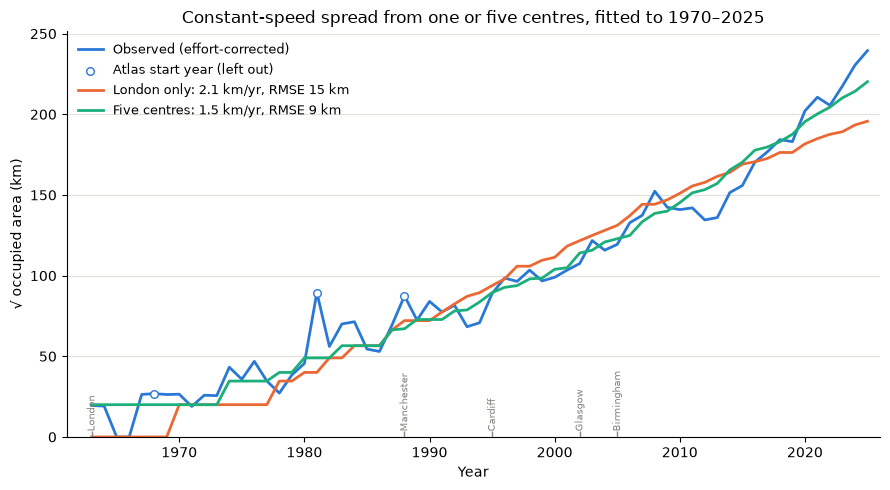

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

used = ~observed.index.isin(ATLAS_START_YEARS)
ax.plot(observed.index, observed, color=OBSERVED, linewidth=2, label="Observed (effort-corrected)")
ax.scatter(observed.index[~used], observed[~used], facecolors="white", edgecolors=OBSERVED,
           s=30, zorder=3, label="Atlas start year (left out)")

for name, colour in [("London only", LONDON_ONLY), ("Five centres", FIVE_CENTRES)]:
    f = fits[name]
    ax.plot(curves[name].index, curves[name], color=colour, linewidth=2,
            label=f"{name}: {f['speed']:.1f} km/yr, RMSE {rmse_from_sse(f['sse']):.0f} km")

for name, t0 in fits["Five centres"]["starts"].items():
    ax.annotate(name, (t0, 0), xytext=(0, 4), textcoords="offset points", rotation=90,
                ha="center", va="bottom", fontsize=7, color=MUTED)
    ax.plot([t0], [0], marker="|", color=MUTED, markersize=8)

ax.set_xlim(FIRST_YEAR - 2, LAST_YEAR + 1)
ax.set_ylim(bottom=0)
ax.set_xlabel("Year")
ax.set_ylabel("√ occupied area (km)")
ax.set_title(f"Constant-speed spread from one or five centres, fitted to {FIT_START}–{LAST_YEAR}")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "spread_model_curves.png", dpi=200)

## How well are the parameters determined?

1. **Near-best solutions:** the five-centre searches that end within 5% of the best RMSE. If their start years differ widely, the data don't determine them.
2. **Speed profile:** for each fixed speed, the best RMSE over the start years. A narrow dip means the speed is well determined. For London exhaustively; for five centres by coordinate descent from the best solution and 3 random starting points per speed.

In [7]:
best_rmse = rmse_from_sse(solutions[0][2])
near_best = pd.DataFrame([{"speed c (km/yr)": c, **s, "RMSE": rmse_from_sse(e)}
                          for c, s, e in solutions if rmse_from_sse(e) <= 1.05 * best_rmse])
near_best = near_best.drop_duplicates()
print(f"{len(near_best)} of {N_RESTARTS} searches within 5% of the best RMSE ({best_rmse:.2f} km)")
display(near_best.round(2))
near_best.agg(["min", "max"]).round(2)

8 of 40 searches within 5% of the best RMSE (8.77 km)


,speed c (km/yr),London,Birmingham,Manchester,Glasgow,Cardiff,RMSE
0,1.50,1963,2005,1988,2002,1995,8.77
1,1.56,1964,1998,2003,2003,1990,9.03
2,1.62,1964,2000,2003,2003,1995,9.06
3,1.50,1963,1999,2004,2006,1984,9.10
4,1.62,1965,2000,2005,2007,1990,9.10
5,1.46,1963,2004,1998,2000,1983,9.13
6,1.62,1965,2007,1990,1999,2007,9.17
7,1.56,1964,2008,1998,1991,1998,9.17


,speed c (km/yr),London,Birmingham,Manchester,Glasgow,Cardiff,RMSE
min,1.46,1963,1998,1988,1991,1983,8.77
max,1.62,1965,2008,2005,2007,2007,9.17


speed,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,...,2.1,2.2,2.3,2.4,2.5,2.6,2.7,2.8,2.9,3.0
London only,68.32,62.08,55.62,48.76,42.83,35.82,30.11,24.83,20.92,17.92,...,15.18,15.45,15.99,16.61,17.65,18.65,19.42,20.78,22.14,23.07
Five centres,27.19,17.32,12.01,11.66,11.18,10.07,10.02,8.76,9.12,9.79,...,11.31,12.50,13.85,15.02,16.40,17.69,18.85,20.42,21.53,22.84


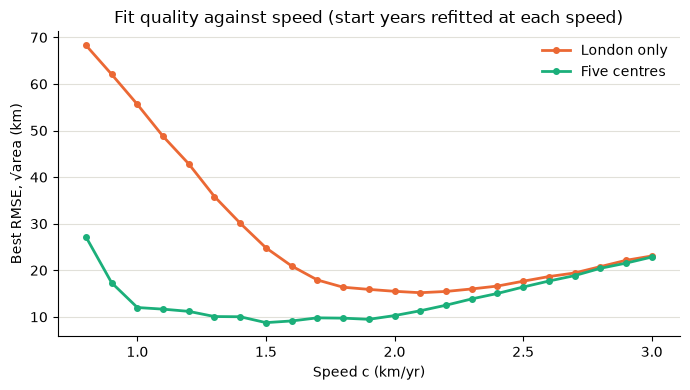

In [8]:
PROFILE_SPEEDS = np.arange(0.8, 3.01, 0.1)
profile_rng = np.random.default_rng(SEED)
london_errors = pd.DataFrame(london_grid, columns=["sse", "speed", "start"])

profile = []
for c in PROFILE_SPEEDS:
    london_best = london_errors.loc[np.isclose(london_errors["speed"], c), "sse"].min()
    inits = [fits["Five centres"]["starts"]] + [random_starts(profile_rng, CENTRES) for _ in range(3)]
    five_best = min(coordinate_descent(s, c=c)[2] for s in inits)
    profile.append({"speed": c, "London only": rmse_from_sse(london_best), "Five centres": rmse_from_sse(five_best)})
profile = pd.DataFrame(profile).set_index("speed")

fig, ax = plt.subplots(figsize=(7, 4))
for name, colour in [("London only", LONDON_ONLY), ("Five centres", FIVE_CENTRES)]:
    ax.plot(profile.index, profile[name], color=colour, linewidth=2, marker="o", markersize=4, label=name)
ax.set_xlabel("Speed c (km/yr)")
ax.set_ylabel("Best RMSE, √area (km)")
ax.set_title("Fit quality against speed (start years refitted at each speed)")
ax.legend(frameon=False)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(FIGURES / "spread_model_speed_profile.png", dpi=200)
profile.round(2).T

## Maps: model against observed squares

Five-centre fit against the squares with parakeet records in the same year (not effort-corrected; before about 2008 many squares were not visited, so "model only" is inflated in 1990 and 2005).

In [9]:
MAP_YEARS = [1990, 2005, 2015, 2025]
five = fits["Five centres"]
five_occupancy = occupancy(five["speed"], five["starts"])


def model_set(year):
    return set(gb_index[five_occupancy[years == year][0]])


rows = []
for year in MAP_YEARS:
    m = model_set(year)
    for obs_name, sets in [("all", parakeet_sets), ("persistent", persistent_sets)]:
        o = sets.get(year, set()) & set(gb_index)
        rows.append({
            "year": year, "observed squares": obs_name,
            "model": len(m), "observed": len(o), "both": len(m & o),
            "share of observed inside model": len(m & o) / len(o),
            "share of model observed": len(m & o) / len(m),
        })
map_comparison = pd.DataFrame(rows)
map_comparison.round(2)

,year,observed squares,model,observed,both,share of observed inside model,share of model observed
0,1990,all,53,35,14,0.40,0.26
1,1990,persistent,53,17,11,0.65,0.21
2,2005,all,151,121,58,0.48,0.38
3,2005,persistent,151,83,52,0.63,0.34
4,2015,all,290,224,113,0.50,0.39
5,2015,persistent,290,161,99,0.61,0.34
6,2025,all,485,543,281,0.52,0.58
7,2025,persistent,485,369,231,0.63,0.48


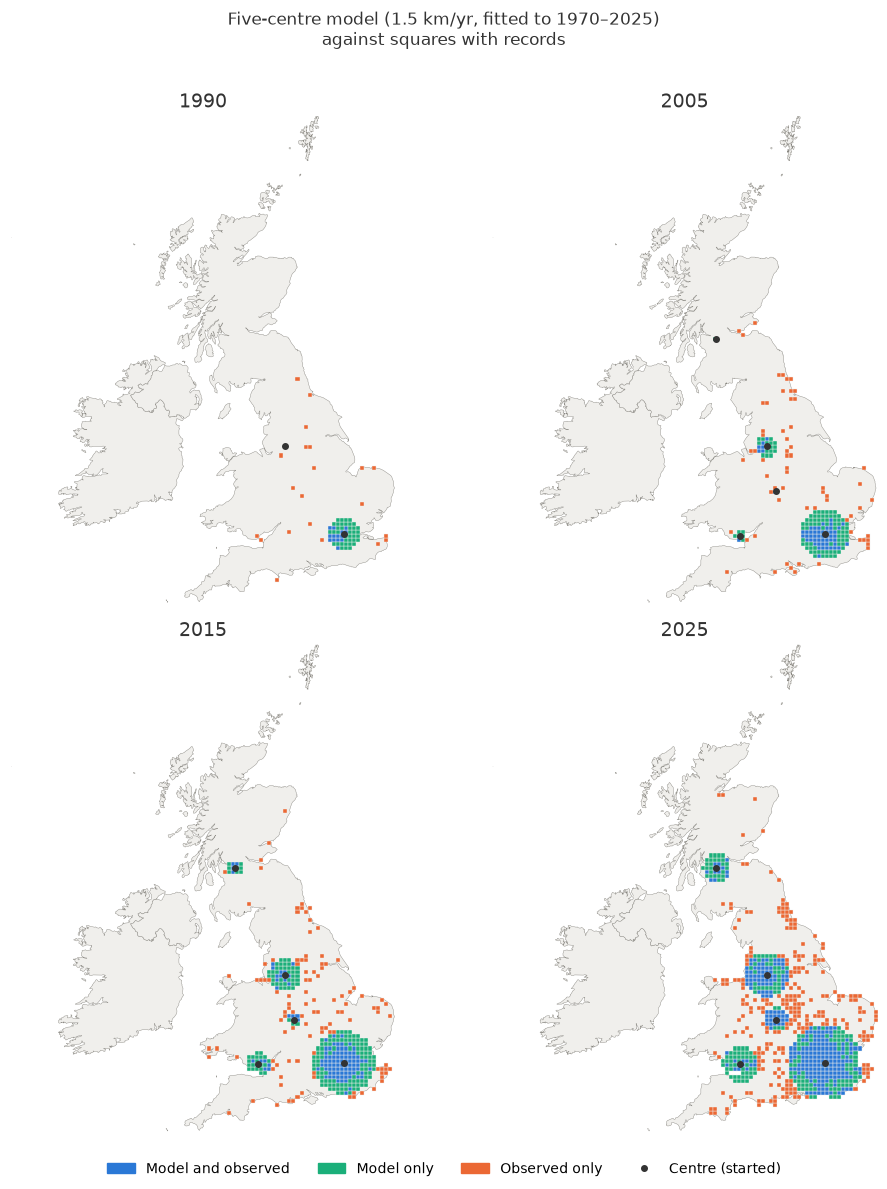

In [10]:
# One polygon per GB land square (km), for drawing
import geopandas as gpd
from shapely.geometry import box

square_polys = gpd.GeoSeries([box(e, n, e + 10, n + 10) for e, n in corner], index=gb_index)
countries = load_countries(LAND_PATH)
land = (countries[countries["ADM0_A3"].isin(["GBR", "IRL", "IMN"])].to_crs("EPSG:27700")
        .geometry.scale(xfact=0.001, yfact=0.001, origin=(0, 0)))  # metres -> km
xmin, ymin = corner.min(axis=0)
xmax, ymax = corner.max(axis=0) + 10

CATEGORIES = [("both", "Model and observed", OBSERVED),
              ("model", "Model only", FIVE_CENTRES),
              ("observed", "Observed only", LONDON_ONLY)]

fig, axes = plt.subplots(2, 2, figsize=(10, 12))
for ax, year in zip(axes.ravel(), MAP_YEARS):
    m = model_set(year)
    o = parakeet_sets.get(year, set()) & set(gb_index)
    groups = {"both": m & o, "model": m - o, "observed": o - m}

    land.plot(ax=ax, color=LAND, edgecolor=LAND_EDGE, linewidth=0.3)
    for key, _, colour in CATEGORIES:
        if groups[key]:
            square_polys.loc[sorted(groups[key])].plot(ax=ax, color=colour, edgecolor=LAND, linewidth=0.3)
    for name, (x, y) in CENTRES.items():
        if year >= five["starts"][name]:
            ax.plot(x, y, marker="o", markersize=4, color=TEXT)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(str(year), fontsize=14, color=TEXT)

handles = [Patch(color=colour, label=label) for _, label, colour in CATEGORIES]
handles.append(Line2D([], [], marker="o", linestyle="", color=TEXT, markersize=4, label="Centre (started)"))
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=10)
fig.suptitle(f"Five-centre model ({five['speed']:.1f} km/yr, fitted to {FIT_START}–{LAST_YEAR})\n"
             "against squares with records", fontsize=12, color=TEXT)
plt.tight_layout(rect=(0, 0.03, 1, 0.97))
fig.savefig(FIGURES / "spread_model_maps.png", dpi=200)

## Squares the model doesn't reach

Observed squares in 2025 outside the five-centre model, grouped by the nearest of a longer list of cities (within 40 km). Clusters of persistent squares here are candidates for further centres; scattered single squares are more likely wandering birds or one-off records.

In [11]:
OTHER_CITIES = {
    **CENTRES,
    "Bristol": (359, 173), "Leeds": (430, 433), "Sheffield": (435, 387), "Newcastle": (425, 565),
    "Edinburgh": (325, 673), "Liverpool": (335, 390), "Nottingham": (457, 340), "Southampton": (442, 112),
    "Brighton": (531, 105), "East Kent": (635, 168), "Oxford": (451, 206), "Norwich": (623, 308),
}

model_2025 = model_set(LAST_YEAR)
outside = pd.DataFrame({"hectad": sorted(parakeet_sets[LAST_YEAR] & set(gb_index) - model_2025)})
outside[["e", "n"]] = outside["hectad"].str.split("_", expand=True).astype(int) + 5
outside["persistent"] = outside["hectad"].isin(persistent_sets[LAST_YEAR])


def nearest_city(row, max_km=40):
    dist = {name: np.hypot(row["e"] - x, row["n"] - y) for name, (x, y) in OTHER_CITIES.items()}
    name = min(dist, key=dist.get)
    return name if dist[name] <= max_km else "elsewhere"


outside["near"] = outside.apply(nearest_city, axis=1)
print(f"{len(outside)} of {len(parakeet_sets[LAST_YEAR] & set(gb_index))} observed squares in {LAST_YEAR} "
      f"are outside the model; {outside['persistent'].sum()} of them persistent")
(outside.groupby("near").agg(squares=("hectad", "size"), persistent=("persistent", "sum"))
 .sort_values("squares", ascending=False))

262 of 543 observed squares in 2025 are outside the model; 138 of them persistent


,squares,persistent
near,,
elsewhere,140,59
Nottingham,23,15
Southampton,16,9
Newcastle,14,14
Birmingham,11,9
Norwich,11,4
Leeds,10,6
Bristol,9,2
East Kent,9,8


## Cardiff: coast instead of circle?

Are the occupied squares near Cardiff concentrated on the coast rather than spread in a circle?

1. **Coast:** distance from each square's centre to the coast (Natural Earth outline; centres in the sea count as 0 km). Squares with parakeet records in at least 2 years within 80 km of Cardiff, against all land squares within 80 km.
2. **Timing:** first parakeet year of each occupied square on the Welsh side (a box west of the Severn, 200–335 km east, 150–260 km north). A front moving along the coast would reach Swansea (55–65 km west) decades after Cardiff.
3. **Recording effort:** coastal squares may simply have more birdwatchers. Proxy: GBIF benchmark records per square, 2010–2025 (`gbif_benchmark_squares.csv.gz`; NBN has no record counts here). Welsh-side squares are split into thirds by this effort, and coastal and inland squares are compared within each third.

In [12]:
import shapely

GBIF_BENCH_PATH = Path("../data/processed/gbif_benchmark_squares.csv.gz")  # 04_effort-correction
COAST_KM = 5  # "coastal" = square centre within 5 km of the coast

uk = countries.loc[countries["ADM0_A3"] == "GBR"].to_crs("EPSG:27700").geometry.union_all()
points = shapely.points(square_centre * 1000)
coast_km = np.where(shapely.contains(uk, points), shapely.distance(points, uk.boundary) / 1000, 0)

squares = pd.DataFrame({"e": square_centre[:, 0], "n": square_centre[:, 1], "coast_km": coast_km},
                       index=gb_index)
cx, cy = CENTRES["Cardiff"]
squares["km_from_cardiff"] = np.hypot(squares["e"] - cx, squares["n"] - cy)
squares["first_year"] = parakeet.groupby("hectad")["year"].min()

rows = []
for start, end in [(1972, 2009), (2010, LAST_YEAR)]:
    n_years = parakeet[parakeet["year"].between(start, end)].groupby("hectad")["year"].nunique()
    ring = squares[squares["km_from_cardiff"] <= 80]
    occupied = ring[ring.index.map(n_years).fillna(0) >= 2]
    rows.append({
        "period": f"{start}–{end}",
        "land squares": len(ring),
        "occupied (2+ years)": len(occupied),
        f"occupied within {COAST_KM} km of coast": (occupied["coast_km"] <= COAST_KM).mean(),
        f"land within {COAST_KM} km of coast": (ring["coast_km"] <= COAST_KM).mean(),
        "median coast km, occupied": occupied["coast_km"].median(),
        "median coast km, land": ring["coast_km"].median(),
    })
pd.DataFrame(rows).set_index("period").round(2)

,land squares,occupied (2+ years),occupied within 5 km of coast,land within 5 km of coast,"median coast km, occupied","median coast km, land"
period,,,,,,
1972–2009,189,29,0.55,0.21,3.79,18.72
2010–2025,189,47,0.32,0.21,9.77,18.72


In [13]:
# Welsh side: occupied squares (records in 2+ years, all years) by first parakeet year
wales = squares[squares["e"].between(200, 335) & squares["n"].between(150, 260)].copy()
wales["n_years"] = wales.index.map(parakeet.groupby("hectad")["year"].nunique()).fillna(0)
wales["occupied"] = wales["n_years"] >= 2
wales["coastal"] = wales["coast_km"] <= COAST_KM

print(f"{wales['occupied'].sum()} of {len(wales)} Welsh-side squares occupied; first 10 by first year:")
(wales[wales["occupied"]].sort_values("first_year")
 [["first_year", "n_years", "coast_km", "km_from_cardiff"]].head(10).round(1))

30 of 125 Welsh-side squares occupied; first 10 by first year:


,first_year,n_years,coast_km,km_from_cardiff
330_160,1972.0,9.0,1.7,20.2
310_170,1974.0,27.0,4.0,3.2
320_170,1975.0,8.0,0.0,7.1
310_180,1980.0,15.0,10.7,9.5
310_160,1980.0,15.0,0.0,11.4
250_190,1981.0,7.0,0.4,65.8
250_200,1981.0,3.0,5.5,69.4
260_190,1981.0,17.0,2.3,56.3
310_220,1981.0,2.0,43.4,49.1
290_180,1983.0,5.0,13.2,24.7


In [14]:
# Recording effort: GBIF benchmark records per square, 2010–2025
gbif_bench = pd.read_csv(GBIF_BENCH_PATH)
effort = gbif_bench[gbif_bench["year"].between(2010, LAST_YEAR)].groupby("hectad")["n_records"].sum()
wales["benchmark_records"] = wales.index.map(effort).fillna(0)
wales["effort third"] = pd.qcut(wales["benchmark_records"], 3, labels=["low", "middle", "high"])

display(wales.groupby("coastal").agg(squares=("occupied", "size"),
                                     median_benchmark_records=("benchmark_records", "median"),
                                     share_occupied=("occupied", "mean")).round(2))
(wales.groupby(["effort third", "coastal"], observed=True)
 .agg(squares=("occupied", "size"), share_occupied=("occupied", "mean")).round(2))

,squares,median_benchmark_records,share_occupied
coastal,,,
False,84,311.5,0.20
True,41,801.0,0.32


squares  share_occupied
effort third coastal                         
low          False         33            0.06
             True           9            0.00
middle       False         26            0.12
             True          15            0.20
high         False         25            0.48
             True          17            0.59

**Result.**

- **Not a circle, but the coastal belt.** Before 2010, 55% of the occupied squares within 80 km of Cardiff are within 5 km of the coast, against 21% of all land squares (median 4 km against 19 km). From 2010 the bias is weaker (32%), partly because squares around Bristol, across the Severn, fill in. The valleys and uplands north of Cardiff stay almost empty for 50 years.
- **Not a front along the coast.** The Swansea squares, 55–65 km from Cardiff, are occupied by 1983 at the latest: Winter Atlas records (1981–84), then local records from 1983 (INNS Data, NRW). That is about ten years after Cardiff's first records, so about 6 km/yr, far faster than the fitted speed. A separate population, or birds moving between coastal towns, fits better than gradual spread.
- **Coast, towns and birdwatchers coincide.** Coastal squares on the Welsh side have about 2.6 times as many benchmark records as inland squares. Within the same effort third, the coastal excess is small (e.g. 59% against 48% occupied in the top third), and each group has only 9–33 squares.

So the Cardiff population stayed in the coastal urban belt and hardly spread inland. These data can't separate coast, towns and observer effort.

## Conclusions

**Five centres fit much better than London alone.**

| | London only | Five centres |
|---|---|---|
| Speed | 2.1 km/yr | 1.5 km/yr |
| Start years | London 1970 | London 1963, Manchester 1988, Cardiff 1995, Glasgow 2002, Birmingham 2005 |
| RMSE 1970–2025 | 15.1 km | 8.8 km |
| RMSE 1970–2009 / 2010–2025 | 11.3 / 21.6 km | 7.1 / 11.8 km |

- **Speed:** the best five-centre fit is 1.5 km/yr; fits within 10% of the best RMSE range from 1.5 to 1.9 km/yr (speed profile). That matches the 1.7 km/yr before 2010 from `04`. London alone needs a higher speed (2.1 km/yr) and still bends the wrong way after 2010, because its circle reaches the coast.
- **Start years:** London starts at the lower bound (1963, 5 years before its first record), so the fit would place it even earlier. The other start years are poorly determined: near-best fits put Manchester anywhere from 1988 to 2005, Glasgow 1991–2007, Birmingham 1998–2008 and Cardiff 1983–2007. What is consistent is the order: London first, the other cities from the late 1980s to the 2000s. Fitting to the maps rather than the total area would pin them down better.
- **The acceleration:** with one constant speed, the five-centre curve's own spread rate rises from 1.7 km/yr (1970–2009) to 2.8 km/yr (2010–2025), against 1.7 → 4.0 observed. So new centres account for about half of the acceleration; the model falls behind the observed range after 2020.
- **The share depends on the window.** The observed range peaks in 2008, stalls until 2013 (after Bird Atlas 2007–11) and then rises at 4.4 km/yr. A smooth constant-speed model can't follow a stall followed by a steep rise. Over windows that span the stall, the observed rate is lower (2005–2025: 3.1 km/yr; 2007–2025: 3.3) and the model (2.8) accounts for about 70–75% of the acceleration. If the 2008 peak and the stall are recording artefacts, part of the steep rise is catch-up; the data can't tell.
- **Maps:** about half of the observed squares lie inside the circles (52% in 2025; 63% of persistent squares). London fits well; Cardiff's circle is mostly empty (see "Cardiff: coast instead of circle?"). 262 of 543 observed squares in 2025 lie outside all five circles: clusters near Nottingham, Southampton, Newcastle, Birmingham's edge and East Kent, and many scattered squares.

**Caveats:** the observer effect (cities have more birdwatchers and more escapes; not corrected); the start years are fitted to the total area only; circles ignore sea and habitat.